# Практическая работа № 4. Регрессионная модель

**Выполнил:** Алмасов Арсен

**Цель:** предсказать месячный доход клиентов с помощью линейной регрессии и оценить качество модели.

## 1. Импорт библиотек и загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("customers_dirty.csv")

print("Размер исходных данных:", df.shape)
display(df.head())
print("\\nПропуски по столбцам:")
print(df.isnull().sum())

Размер исходных данных: (30, 6)


,customer_id,age,monthly_income,city,visits_per_month,satisfaction_score
0,1,19.0,18000.0,Бишкек,5,8.0
1,2,22.0,25000.0,Ош,8,9.0
2,3,25.0,32000.0,Бишкек,12,7.0
3,4,31.0,45000.0,Каракол,6,8.0
4,5,28.0,38000.0,Ош,10,9.0


\nПропуски по столбцам:
customer_id           0
age                   1
monthly_income        1
city                  0
visits_per_month      0
satisfaction_score    1
dtype: int64


## 2. Подготовка признаков и целевой переменной

In [2]:
# Целевая переменная — месячный доход клиента.
# Строки без известного дохода нельзя использовать для обучения и оценки.

df = df.dropna(subset=["monthly_income"]).copy()

X = df[["age", "city", "visits_per_month", "satisfaction_score"]]
y = df["monthly_income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)
print("Количество объектов для обучения:", len(X_train))
print("Количество объектов для тестирования:", len(X_test))

Размер train: (23, 4)
Размер test: (6, 4)
Количество объектов для обучения: 23
Количество объектов для тестирования: 6


## 3. Создание пайплайна предобработки

In [3]:
numeric_features = [
    "age", "visits_per_month", "satisfaction_score"
]
categorical_features = ["city"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Пайплайн предобработки и модель созданы.")

Пайплайн предобработки и модель созданы.


## 4. Обучение модели и предсказания

In [4]:
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Модель обучена.")
print("Первые предсказания:", np.round(y_pred[:5], 2))
print("Первые реальные значения:", y_test.iloc[:5].to_list())

Модель обучена.
Первые предсказания: [31400.6  31841.1  33455.83 28610.82 31136.69]
Первые реальные значения: [19000.0, 36000.0, 950000.0, 39000.0, 28000.0]


## 5. Оценка качества модели

In [5]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.3f}")

print(f"\nИнтерпретация MAE: в среднем модель ошибается примерно на {mae:.2f} единиц дохода.")

if r2 >= 0:
    print(f"Модель объясняет около {r2 * 100:.1f}% разброса доходов в тестовой выборке.")
else:
    print("R² меньше нуля: на тестовых данных модель работает хуже простого прогноза средним значением.")

MAE: 157795.86
RMSE: 374241.92
R²: -0.198

Интерпретация MAE: в среднем модель ошибается примерно на 157795.86 единиц дохода.
R² меньше нуля: на тестовых данных модель работает хуже простого прогноза средним значением.


## 6. Анализ коэффициентов модели

In [6]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["regressor"].coef_

coef_df = pd.DataFrame({
    "Признак": feature_names,
    "Коэффициент": coefficients,
    "Модуль коэффициента": np.abs(coefficients)
}).sort_values("Модуль коэффициента", ascending=False)

display(coef_df)

strongest = coef_df.iloc[0]
print("Наибольший по модулю коэффициент:")
print(strongest["Признак"], "=", round(strongest["Коэффициент"], 3))

print("\nКоэффициенты показывают связь признаков с прогнозом дохода при фиксированных остальных признаках.")
print("Числовые признаки масштабированы, поэтому их коэффициенты относятся к стандартизированным значениям.")

,Признак,Коэффициент,Модуль коэффициента
6,categorical__city_неизвестно,12869.289582,12869.289582
4,categorical__city_Каракол,-8938.885203,8938.885203
0,numeric__age,3980.769254,3980.769254
2,numeric__satisfaction_score,3436.671085,3436.671085
1,numeric__visits_per_month,3038.523821,3038.523821
5,categorical__city_Ош,-2637.725305,2637.725305
3,categorical__city_Бишкек,-1292.679074,1292.679074


Наибольший по модулю коэффициент:
categorical__city_неизвестно = 12869.29

Коэффициенты показывают связь признаков с прогнозом дохода при фиксированных остальных признаках.
Числовые признаки масштабированы, поэтому их коэффициенты относятся к стандартизированным значениям.


## 7. График: предсказанный доход против реального

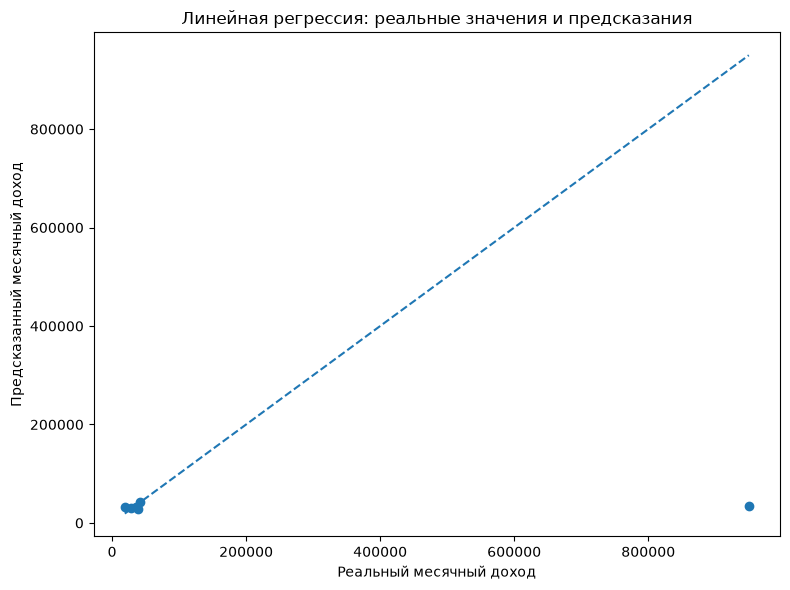

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Реальный месячный доход")
plt.ylabel("Предсказанный месячный доход")
plt.title("Линейная регрессия: реальные значения и предсказания")
plt.tight_layout()
plt.show()

## 8. Выводы

- Данные разделены на обучающую и тестовую выборки в пропорции 80/20.
- Пропуски в признаках обрабатываются внутри Pipeline.
- Город кодируется OneHotEncoder, числовые признаки масштабируются StandardScaler.
- Линейная регрессия обучена на train, а качество оценено на test.
- MAE показывает среднюю ошибку прогноза в единицах месячного дохода.
- RMSE сильнее учитывает большие ошибки, а R² показывает, насколько модель объясняет разброс целевой переменной.
- Коэффициенты помогают понять вклад обработанных признаков, но не доказывают причинно-следственную связь.
- Датасет небольшой и содержит необычные значения, поэтому результаты нужно интерпретировать осторожно.